In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy.stats import t

data = load_breast_cancer()
X = data.data
y = data.target

y = np.where(y == 0, -1, 1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_b = np.hstack([np.ones((X_scaled.shape[0], 1)), X_scaled])

X_train, X_test, y_train, y_test = train_test_split(X_b, y, test_size=0.2, random_state=42)

In [40]:
from ridge_linear import RidgeLinearClassifier, accuracy
alphas_ridge = np.logspace(-3, 3, 20)
best_alpha_ridge = None
best_acc_ridge = 0

for alpha in alphas_ridge:
    model = RidgeLinearClassifier(alpha=alpha)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy(y_test, preds)
    if acc > best_acc_ridge:
        best_acc_ridge = acc
        best_alpha_ridge = alpha

print(f"Best alpha for Ridge: {best_alpha_ridge:.4f}, Accuracy test: {best_acc_ridge:.4f}")

Best alpha for Ridge: 1.4384, Accuracy test: 0.9649


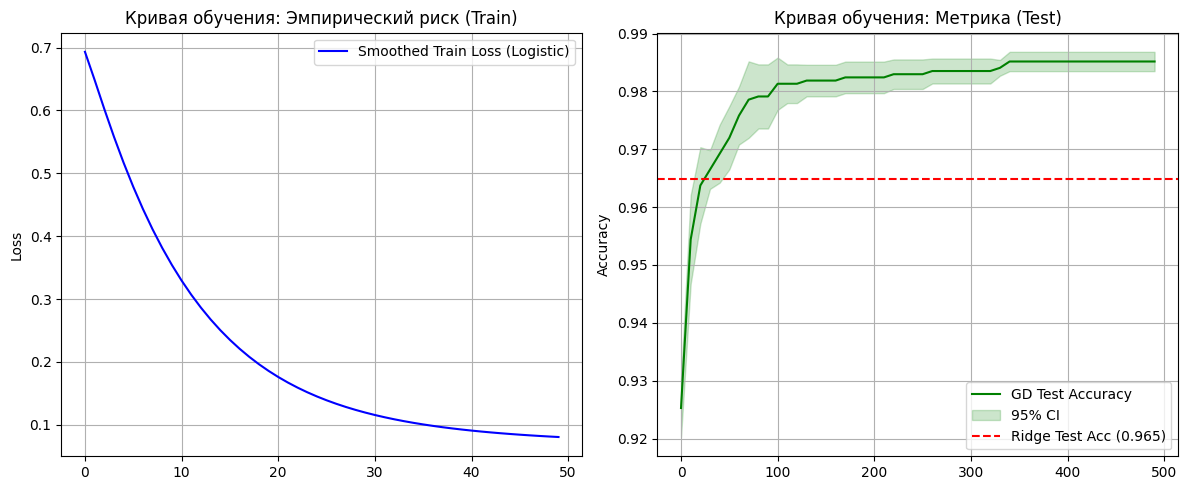

In [41]:
from linear_gd import LinearClassifierGD

gd_params = {'loss_type': 'logistic', 'lr': 0.1, 'lambda1': 0.001, 'lambda2': 0.001, 'epochs': 500}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
train_losses = []
test_accs = []

for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    model = LinearClassifierGD(**gd_params)
    model.fit(X_tr, y_tr)

    train_losses.append(model.history['loss'])
    test_accs.append(model.history['acc'])

train_losses = np.array(train_losses)
test_accs = np.array(test_accs)

def smooth_curve(points, factor=0.9):
    smoothed = []
    for point in points:
        if smoothed:
            previous = smoothed[-1]
            smoothed.append(previous * factor + point * (1 - factor))
        else:
            smoothed.append(point)
    return np.array(smoothed)

mean_train_loss = np.mean(train_losses, axis=0)
smoothed_train_loss = smooth_curve(mean_train_loss)

mean_test_acc = np.mean(test_accs, axis=0)
std_test_acc = np.std(test_accs, axis=0)

# trust: 95%
n_folds = 5
t_val = t.ppf(0.975, df=n_folds-1)
ci_test_acc = t_val * std_test_acc / np.sqrt(n_folds)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(smoothed_train_loss, label='Smoothed Train Loss (Logistic)', color='blue')
plt.title('Кривая обучения: Эмпирический риск (Train)')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
iterations = np.arange(len(mean_test_acc)) * 10
plt.plot(iterations, mean_test_acc, label='GD Test Accuracy', color='green')
plt.fill_between(iterations, mean_test_acc - ci_test_acc, mean_test_acc + ci_test_acc,
                 color='green', alpha=0.2, label='95% CI')

plt.axhline(y=best_acc_ridge, color='red', linestyle='--', label=f'Ridge Test Acc ({best_acc_ridge:.3f})')

plt.title('Кривая обучения: Метрика (Test)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

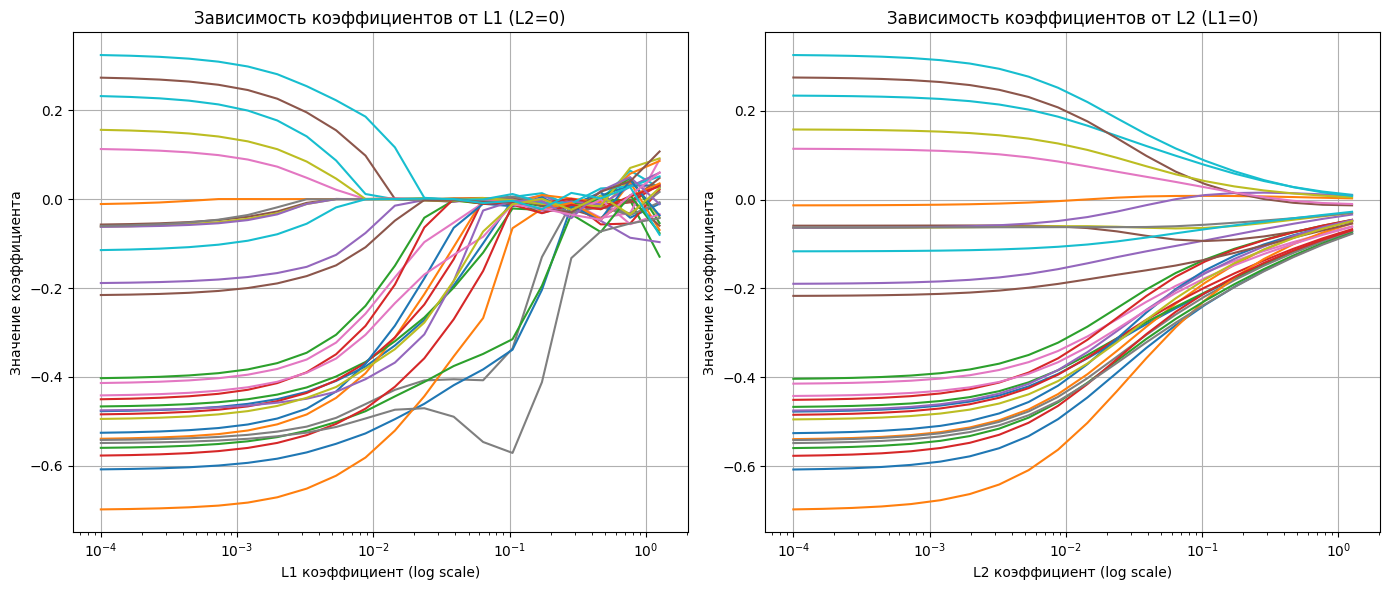

In [42]:
alphas = np.logspace(-4, 0.1, 20)
weights_l1 = []
weights_l2 = []

for alpha in alphas:
    model = LinearClassifierGD(loss_type='logistic', lr=0.1, lambda1=alpha, lambda2=0.0, epochs=300)
    model.fit(X_train, y_train)
    weights_l1.append(model.w.copy())

for alpha in alphas:
    model = LinearClassifierGD(loss_type='logistic', lr=0.1, lambda1=0.0, lambda2=alpha, epochs=300)
    model.fit(X_train, y_train)
    weights_l2.append(model.w.copy())

weights_l1 = np.array(weights_l1)
weights_l2 = np.array(weights_l2)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for i in range(1, weights_l1.shape[1]):
    plt.plot(alphas, weights_l1[:, i], label=f'Feature {i}')
plt.xscale('log')
plt.title('Зависимость коэффициентов от L1 (L2=0)')
plt.xlabel('L1 коэффициент (log scale)')
plt.ylabel('Значение коэффициента')
plt.grid(True)

plt.subplot(1, 2, 2)
for i in range(1, weights_l2.shape[1]):
    plt.plot(alphas, weights_l2[:, i], label=f'Feature {i}')
plt.xscale('log')
plt.title('Зависимость коэффициентов от L2 (L1=0)')
plt.xlabel('L2 коэффициент (log scale)')
plt.ylabel('Значение коэффициента')
plt.grid(True)

plt.tight_layout()
plt.show()

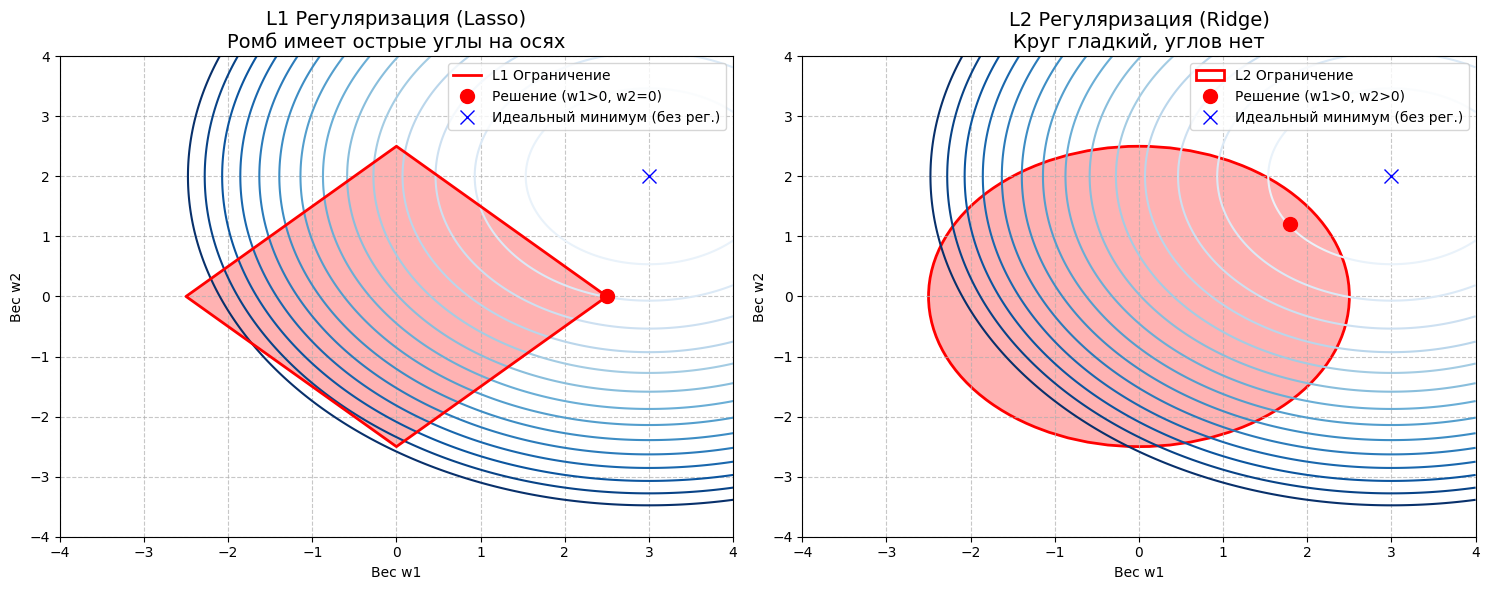

In [44]:
w1 = np.linspace(-4, 4, 400)
w2 = np.linspace(-4, 4, 400)
W1, W2 = np.meshgrid(w1, w2)

Loss = (W1 - 3)**2 + (W2 - 2)**2

budget = 2.5

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax1 = axes[0]
contours = ax1.contour(W1, W2, Loss, levels=np.linspace(0, 30, 15), cmap='Blues')
l1_region = np.abs(W1) + np.abs(W2) <= budget
ax1.contourf(W1, W2, l1_region, levels=[0.5, 1], colors='red', alpha=0.3)
ax1.plot([budget, 0, -budget, 0, budget], [0, budget, 0, -budget, 0], color='red', linewidth=2, label='L1 Ограничение')

ax1.plot(2.5, 0, 'ro', markersize=10, label='Решение (w1>0, w2=0)')
ax1.plot(3, 2, 'bx', markersize=10, label='Идеальный минимум (без рег.)')
ax1.set_title('L1 Регуляризация (Lasso)\n', fontsize=14)
ax1.set_xlabel('Вес w1')
ax1.set_ylabel('Вес w2')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

ax2 = axes[1]
contours = ax2.contour(W1, W2, Loss, levels=np.linspace(0, 30, 15), cmap='Blues')
l2_region = W1**2 + W2**2 <= budget**2
ax2.contourf(W1, W2, l2_region, levels=[0.5, 1], colors='red', alpha=0.3)
circle = plt.Circle((0, 0), budget, color='red', fill=False, linewidth=2, label='L2 Ограничение')
ax2.add_patch(circle)

ax2.plot(1.8, 1.2, 'ro', markersize=10, label='Решение (w1>0, w2>0)')
ax2.plot(3, 2, 'bx', markersize=10, label='Идеальный минимум (без рег.)')
ax2.set_title('L2 Регуляризация (Ridge)\n', fontsize=14)
ax2.set_xlabel('Вес w1')
ax2.set_ylabel('Вес w2')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()